# Bifurcation Analysis of the Plant–Kim R15 Model

## 1. Model setup

The untreated seven-dimensional Plant–Kim model is used as the baseline model, with the maximal inward-current conductance set to $g_I = 4.0$.

To investigate the effect of TTX on the model dynamics, $g_I$ is selected as the continuation parameter. The parameter will be varied from its untreated value toward the TTX endpoint, $g_I = 0$.

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import PyDSTool as dst

from scipy.optimize import brentq

from plant_kim_model import (
    BASELINE_PARS,
    S_I, Z_I, S_K, S_A, Z_A, S_P,
    build_vode_system
)

## 2. Equilibrium calculation

An equilibrium of the untreated model is first calculated to provide the starting solution for equilibrium continuation.

At equilibrium, the gating variables take their voltage-dependent steady-state values. The equilibrium voltage can therefore be obtained by solving

$$
\frac{dV}{dt}=0.
$$

The root is calculated numerically using the baseline parameter set.

In [13]:
def dV_equilibrium(V):
    p = BASELINE_PARS

    X_K = float(S_K(V))
    X_A = float(S_A(V))
    Y_A = float(Z_A(V))
    X_P = float(S_P(V))
    X_I = float(S_I(V))
    Y_I = float(Z_I(V))

    return (1 / p["C"]) * (
        (p["g_I"] * X_I**3 * Y_I + p["g_T"]) * (p["V_I"] - V)
        + (p["g_K"] * X_K**4
           + p["g_A"] * X_A * Y_A
           + p["g_P"] * X_P) * (p["V_K"] - V)
        + p["g_L"] * (p["V_L"] - V)
        + p["I_ep"]
        + p["I_ext"]
    )

V_eq = brentq(dV_equilibrium, -80, 40)

print(f"Equilibrium voltage: {V_eq:.3f} mV")

Equilibrium voltage: -18.312 mV


The untreated model has an equilibrium voltage of approximately $V^* = -18.312$ mV. The corresponding equilibrium values of the six gating variables are calculated below to define the complete seven-dimensional equilibrium state.

In [14]:
eq_ics = {
    "V": float(V_eq),
    "X_K": float(S_K(V_eq)),
    "X_A": float(S_A(V_eq)),
    "Y_A": float(Z_A(V_eq)),
    "X_P": float(S_P(V_eq)),
    "X_I": float(S_I(V_eq)),
    "Y_I": float(Z_I(V_eq)),
}

print("Equilibrium state:")
for name, value in eq_ics.items():
    print(f"{name:3s} = {value:.6f}")

Equilibrium state:
V   = -18.311553
X_K = 0.469303
X_A = 0.894266
Y_A = 0.000192
X_P = 1.000000
X_I = 0.603682
Y_I = 0.037033


The complete equilibrium state above is used as the initial solution for numerical continuation.

## 3. Equilibrium continuation in $g_I$

The maximal inward-current conductance $g_I$ is used as the continuation parameter. Starting from the untreated equilibrium at $g_I = 4.0$, the equilibrium branch is continued toward $g_I = 0$.

Bifurcation points and stability information are recorded along the branch.

The seven-dimensional equilibrium obtained above is used to initialise the Plant–Kim model for continuation. An equilibrium-point continuation (EP-C) curve is then constructed with $g_I$ as the free parameter.

In [15]:
pars = BASELINE_PARS.copy()

ode = build_vode_system(
    pars=pars,
    ics=eq_ics,
    name="PlantKim_gI_cont"
)

PC = dst.ContClass(ode)

print("Continuation object created.")

Continuation object created.


In [16]:
PCargs = dst.args(name="EQ_gI", type="EP-C")

PCargs.freepars = ["g_I"]

PCargs.StepSize = 0.02
PCargs.MinStepSize = 1e-5
PCargs.MaxStepSize = 0.1
PCargs.MaxNumPoints = 300

PCargs.LocBifPoints = "all"
PCargs.SaveEigen = True

PC.newCurve(PCargs)

print("Equilibrium continuation curve configured.")

Equilibrium continuation curve configured.


In [18]:
PC["EQ_gI"].backward()

The detected special point on the equilibrium branch is extracted below to determine its parameter value and membrane potential.

In [26]:
LP1 = PC["EQ_gI"].getSpecialPoint("LP1")

print(f"LP1: g_I = {LP1['g_I']:.4f}")
print(f"     V   = {LP1['V']:.4f} mV")

LP1: g_I = 2.4566
     V   = -26.1342 mV


A limit point (LP1) is detected at approximately

$$
g_I = 2.457, \qquad V = -26.134\ \text{mV}.
$$

At this point, the equilibrium branch folds with respect to $g_I$. Therefore, continuing along the same equilibrium branch beyond LP1 causes $g_I$ to increase again rather than continuing directly toward $g_I = 0$.

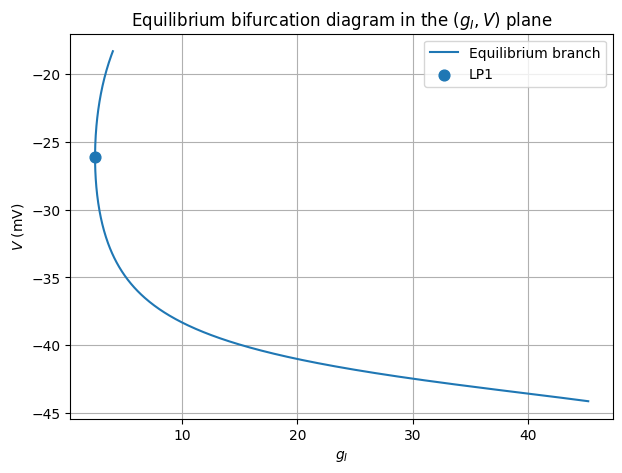

In [27]:
sol = PC["EQ_gI"].sol

gI_vals = sol["g_I"]
V_vals = sol["V"]

plt.figure(figsize=(7, 5))
plt.plot(gI_vals, V_vals, label="Equilibrium branch")

plt.scatter(
    LP1["g_I"],
    LP1["V"],
    s=60,
    label="LP1"
)

plt.xlabel(r"$g_I$")
plt.ylabel(r"$V$ (mV)")
plt.title(r"Equilibrium bifurcation diagram in the $(g_I, V)$ plane")
plt.legend()
plt.grid(True)

plt.show()

The equilibrium branch folds at LP1, located at approximately $g_I = 2.457$ and $V = -26.134$ mV. Beyond this point, continuation along the same branch proceeds toward increasing $g_I$ rather than toward the TTX endpoint $g_I = 0$.

Therefore, this equilibrium branch does not directly extend from the untreated state to $g_I = 0$.

In [28]:
for i in [0, len(sol)//2, len(sol)-1]:
    print(
        f"Point {i}: "
        f"g_I = {sol['g_I'][i]:.4f}, "
        f"V = {sol['V'][i]:.4f}, "
        f"stability = {sol.labels[i]['EP']['data'].get('stab')}"
    )

Point 0: g_I = 45.2134, V = -44.1324, stability = None
Point 300: g_I = 15.6058, V = -40.1052, stability = None
Point 599: g_I = 4.0000, V = -18.3116, stability = None


In [29]:
point = sol.labels[len(sol)-1]["EP"]["data"]

print(point.keys())

['V', 'ds', 'evals', 'evecs']


In [30]:
evals = point["evals"]

print("Eigenvalues at g_I = 4:")
for lam in evals:
    print(lam)

print("\nMaximum real part =", max(lam.real for lam in evals))

Eigenvalues at g_I = 4:
(-0.3014722332603251+0j)
(-0.09999935831178068+0j)
(0.018952408092873293+0.045518037110361204j)
(0.018952408092873293-0.045518037110361204j)
(-0.02240030392848646+0j)
(-0.004252532533113809+0j)
(-0.00012500000078902404+0j)

Maximum real part = 0.018952408092873293


In [31]:
max_real_parts = []

for i in range(len(sol)):
    evals = sol.labels[i]["EP"]["data"]["evals"]
    max_real = max(lam.real for lam in evals)
    max_real_parts.append(max_real)

print("Number of points:", len(max_real_parts))
print("Minimum max real part:", min(max_real_parts))
print("Maximum max real part:", max(max_real_parts))

Number of points: 600
Minimum max real part: 0.018952408092873293
Maximum max real part: 0.06537480535105533


In [32]:
idx_LP = np.argmin(np.abs(gI_vals - LP1["g_I"]))

for i in [idx_LP - 2, idx_LP + 2]:
    evals = sol.labels[i]["EP"]["data"]["evals"]

    print(f"\ng_I = {sol['g_I'][i]:.6f}, V = {sol['V'][i]:.6f}")
    print("Eigenvalues:")
    for lam in evals:
        print(lam)


g_I = 2.457451, V = -26.334054
Eigenvalues:
(-0.28690720488013066+0j)
(-0.09998885289471765+0j)
(0.05947009095502862+0j)
(-0.015252695369591144+0j)
(-0.004114154996775185+0j)
(-0.00044810709713257406+0j)
(-0.0001249819895209493+0j)

g_I = 2.456886, V = -26.012463
Eigenvalues:
(-0.28662381451203445+0j)
(-0.0999900713237353+0j)
(0.05849396893026321+0j)
(-0.015476290928747513+0j)
(-0.004142055673444755+0j)
(0.0002859670012913381+0j)
(-0.00012501162858054128+0j)


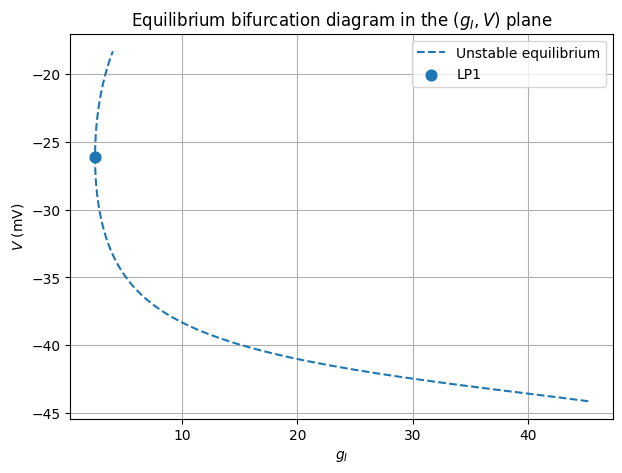

In [33]:
plt.figure(figsize=(7, 5))

plt.plot(
    gI_vals,
    V_vals,
    "--",
    label="Unstable equilibrium"
)

plt.scatter(
    LP1["g_I"],
    LP1["V"],
    s=60,
    label="LP1"
)

plt.xlabel(r"$g_I$")
plt.ylabel(r"$V$ (mV)")
plt.title(r"Equilibrium bifurcation diagram in the $(g_I,V)$ plane")
plt.legend()
plt.grid(True)

plt.show()

## 4. Equilibrium bifurcation diagram and stability

The equilibrium branch obtained in Section 3 is plotted in the $(g_I,V)$ plane. The stability of each equilibrium is determined from the eigenvalues of the Jacobian matrix.

An equilibrium is classified as stable if all eigenvalues have negative real parts. If at least one eigenvalue has a positive real part, the equilibrium is classified as unstable.

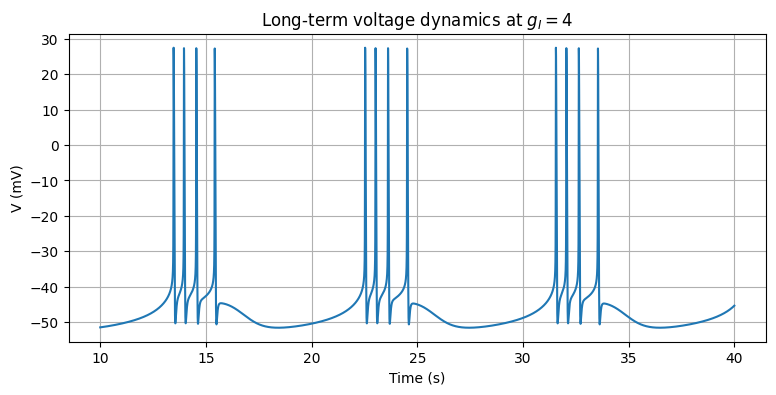

In [53]:
pars = BASELINE_PARS.copy()
pars["g_I"] = 4.0

ode_gI4 = build_vode_system(
    pars=pars,
    name="PlantKim_gI4_long"
)

traj_gI4 = simulate(
    ode_gI4,
    tdata=(0, 40000),
    dt=0.5,
    trajname="gI4_long"
)

t = np.asarray(traj_gI4["t"])
V = np.asarray(traj_gI4["V"])

mask = t >= 10000

plt.figure(figsize=(9, 4))
plt.plot(t[mask] / 1000, V[mask])

plt.xlabel("Time (s)")
plt.ylabel("V (mV)")
plt.title(r"Long-term voltage dynamics at $g_I=4$")
plt.grid(True)

plt.show()

In [36]:
sol = PC["EQ_gI"].sol

gI_vals = sol["g_I"]
V_vals = sol["V"]

max_real_parts = []

for i in range(len(sol)):
    evals = sol.labels[i]["EP"]["data"]["evals"]
    max_real_parts.append(max(lam.real for lam in evals))

max_real_parts = np.array(max_real_parts)

stable = max_real_parts < 0
unstable = max_real_parts > 0

print("Stable equilibrium points:", np.sum(stable))
print("Unstable equilibrium points:", np.sum(unstable))

Stable equilibrium points: 0
Unstable equilibrium points: 600


The equilibrium branch is unstable, indicating that trajectories near these equilibrium states do not return to the equilibrium following a small perturbation.

### 4.1 Equilibrium bifurcation diagram

The equilibrium branch is plotted in the $(g_I,V)$ plane. Since all computed equilibrium points on this branch are unstable, the branch is shown using a dashed line. The detected limit point LP1 is marked separately.

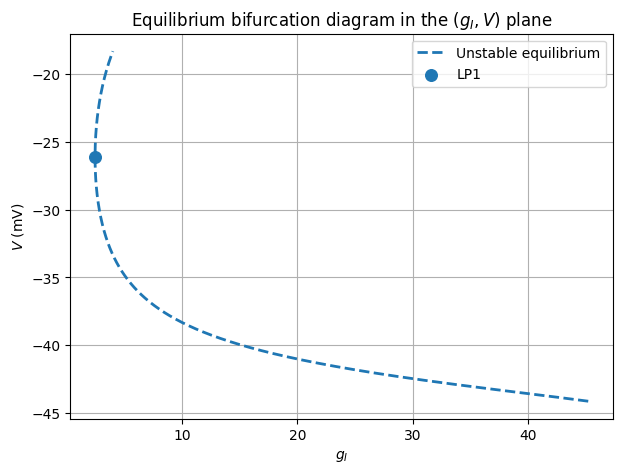

In [37]:
plt.figure(figsize=(7, 5))

plt.plot(
    gI_vals,
    V_vals,
    "--",
    linewidth=2,
    label="Unstable equilibrium"
)

plt.scatter(
    LP1["g_I"],
    LP1["V"],
    s=70,
    zorder=3,
    label="LP1"
)

plt.xlabel(r"$g_I$")
plt.ylabel(r"$V$ (mV)")
plt.title(r"Equilibrium bifurcation diagram in the $(g_I,V)$ plane")

plt.legend()
plt.grid(True)
plt.show()

The equilibrium branch remains unstable as $g_I$ decreases from the untreated value $g_I=4$ to the limit point at approximately

$$
g_I = 2.457,\qquad V = -26.134\ \text{mV}.
$$

At LP1, the equilibrium branch folds and turns toward increasing $g_I$. Therefore, this equilibrium branch cannot be continued directly from $g_I=4$ to the TTX endpoint $g_I=0$.

## 5. Dynamics across the TTX parameter range

The endpoint simulations show that the untreated model at $g_I=4$ exhibits normal bursting, whereas complete TTX blockade at $g_I=0$ removes the fast action potentials while preserving the underlying slow membrane-potential oscillation.

To examine the transition between these two regimes, the model is simulated at five representative values,

$$
g_I = 4,\ 3,\ 2,\ 1,\ 0,
$$

with all other parameters kept at their baseline values.

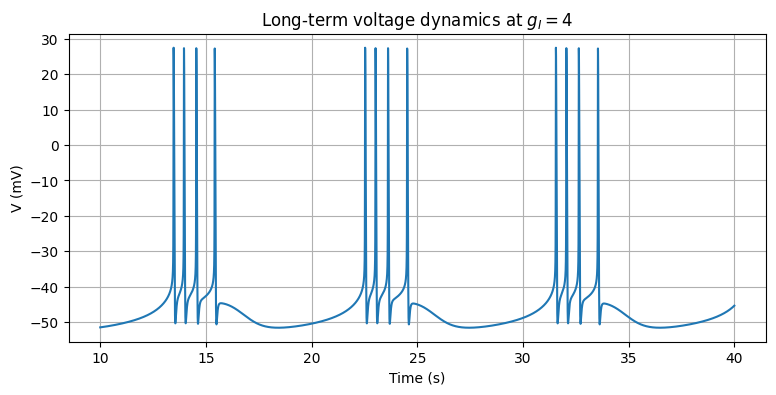

In [54]:
pars = BASELINE_PARS.copy()
pars["g_I"] = 4.0

ode_gI4 = build_vode_system(
    pars=pars,
    name="PlantKim_gI4_long"
)

traj_gI4 = simulate(
    ode_gI4,
    tdata=(0, 40000),
    dt=0.5,
    trajname="gI4_long"
)

t = np.asarray(traj_gI4["t"])
V = np.asarray(traj_gI4["V"])

mask = t >= 10000

plt.figure(figsize=(9, 4))
plt.plot(t[mask] / 1000, V[mask])

plt.xlabel("Time (s)")
plt.ylabel("V (mV)")
plt.title(r"Long-term voltage dynamics at $g_I=4$")
plt.grid(True)

plt.show()

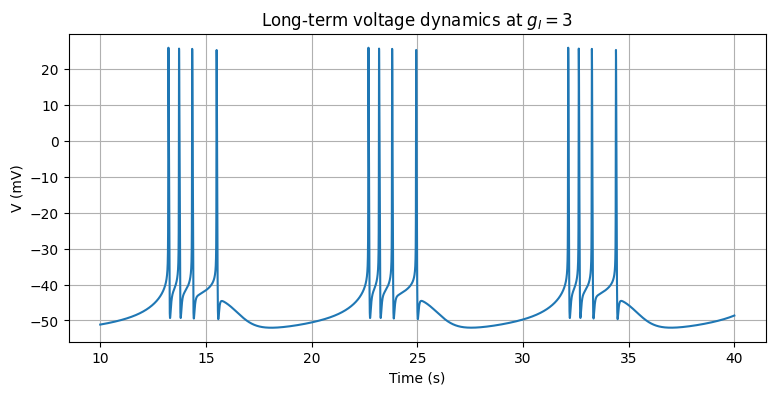

In [51]:
pars = BASELINE_PARS.copy()
pars["g_I"] = 3.0

ode_gI3 = build_vode_system(
    pars=pars,
    name="PlantKim_gI3_long"
)

traj_gI3 = simulate(
    ode_gI3,
    tdata=(0, 40000),
    dt=0.5,
    trajname="gI3_long"
)

t = np.asarray(traj_gI3["t"])
V = np.asarray(traj_gI3["V"])

# Plot the long-term region only
mask = t >= 10000

plt.figure(figsize=(9, 4))
plt.plot(t[mask] / 1000, V[mask])

plt.xlabel("Time (s)")
plt.ylabel("V (mV)")
plt.title(r"Long-term voltage dynamics at $g_I=3$")
plt.grid(True)

plt.show()

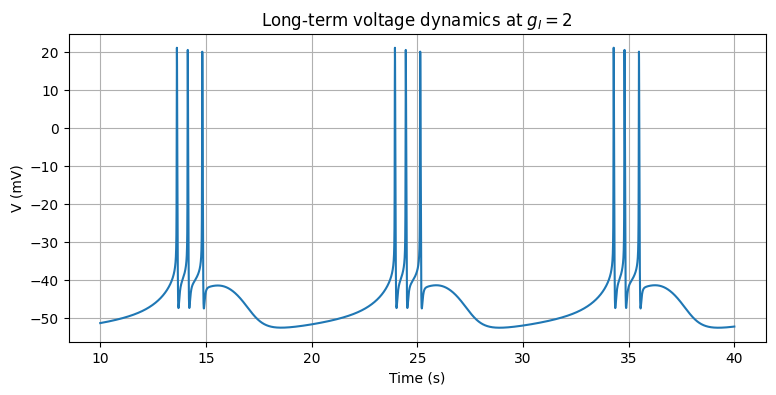

In [52]:
pars = BASELINE_PARS.copy()
pars["g_I"] = 2.0

ode_gI2 = build_vode_system(
    pars=pars,
    name="PlantKim_gI2_long"
)

traj_gI2 = simulate(
    ode_gI2,
    tdata=(0, 40000),
    dt=0.5,
    trajname="gI2_long"
)

t = np.asarray(traj_gI2["t"])
V = np.asarray(traj_gI2["V"])

mask = t >= 10000

plt.figure(figsize=(9, 4))
plt.plot(t[mask] / 1000, V[mask])

plt.xlabel("Time (s)")
plt.ylabel("V (mV)")
plt.title(r"Long-term voltage dynamics at $g_I=2$")
plt.grid(True)

plt.show()

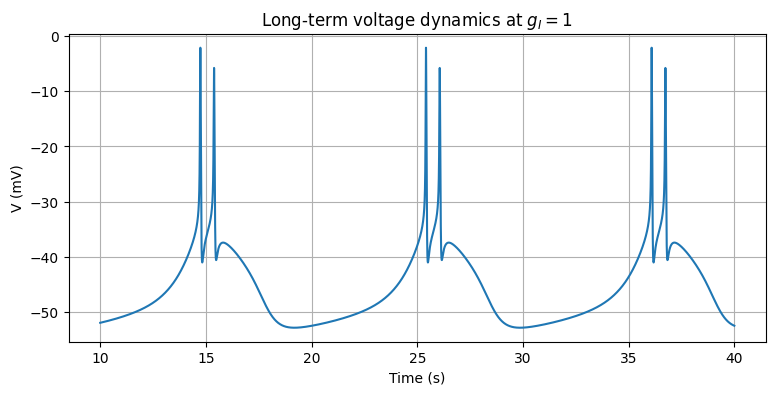

In [55]:
pars = BASELINE_PARS.copy()
pars["g_I"] = 1.0

ode_gI1 = build_vode_system(
    pars=pars,
    name="PlantKim_gI1_long"
)

traj_gI1 = simulate(
    ode_gI1,
    tdata=(0, 40000),
    dt=0.5,
    trajname="gI1_long"
)

t = np.asarray(traj_gI1["t"])
V = np.asarray(traj_gI1["V"])

mask = t >= 10000

plt.figure(figsize=(9, 4))
plt.plot(t[mask] / 1000, V[mask])

plt.xlabel("Time (s)")
plt.ylabel("V (mV)")
plt.title(r"Long-term voltage dynamics at $g_I=1$")
plt.grid(True)
plt.show()

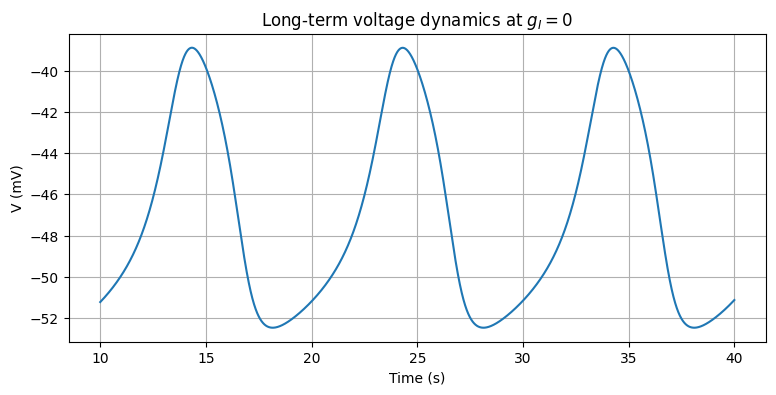

In [56]:
pars = BASELINE_PARS.copy()
pars["g_I"] = 0.0

ode_gI0 = build_vode_system(
    pars=pars,
    name="PlantKim_gI0_long"
)

traj_gI0 = simulate(
    ode_gI0,
    tdata=(0, 40000),
    dt=0.5,
    trajname="gI0_long"
)

t = np.asarray(traj_gI0["t"])
V = np.asarray(traj_gI0["V"])

mask = t >= 10000

plt.figure(figsize=(9, 4))
plt.plot(t[mask] / 1000, V[mask])

plt.xlabel("Time (s)")
plt.ylabel("V (mV)")
plt.title(r"Long-term voltage dynamics at $g_I=0$")
plt.grid(True)
plt.show()

### 5.2 Results

The long-term simulations show a progressive change in the bursting dynamics as $g_I$ is reduced. At $g_I=4$ and $g_I=3$, the model exhibits clear bursting with approximately four fast spikes per burst. At $g_I=2$, the number of fast spikes decreases to approximately three per burst. A further reduction to $g_I=1$ produces approximately two spikes per burst with substantially reduced spike amplitude.

At $g_I=0$, the fast action potentials disappear completely, while the underlying slow membrane-potential oscillation remains. Therefore, decreasing $g_I$ progressively suppresses the fast spiking component of the R15 bursting dynamics, consistent with increasing blockade of the TTX-sensitive inward current.

These simulations also show that the limit point identified in the equilibrium continuation does not correspond directly to the disappearance of bursting, since oscillatory bursting remains present for $g_I<2.457$.

## 6. Quantitative effect of $g_I$ on fast spiking

The long-term simulations indicate that decreasing $g_I$ progressively suppresses the fast spiking component of the bursting dynamics. To quantify this effect, spike peaks are detected from the long-term voltage traces for each value of $g_I$.

In [57]:
from scipy.signal import find_peaks

trajectories = {
    4: traj_gI4,
    3: traj_gI3,
    2: traj_gI2,
    1: traj_gI1,
    0: traj_gI0
}

spike_results = {}

for gI, traj in trajectories.items():

    t = np.asarray(traj["t"])
    V = np.asarray(traj["V"])

    # Analyse only the long-term region: 10–40 s
    mask = t >= 10000
    t_long = t[mask]
    V_long = V[mask]

    # Detect fast action-potential peaks
    peaks, _ = find_peaks(
        V_long,
        height=-20
    )

    spike_results[gI] = {
        "count": len(peaks),
        "times": t_long[peaks],
        "voltages": V_long[peaks]
    }

    print(
        f"g_I = {gI}: "
        f"{len(peaks)} fast spikes detected"
    )

g_I = 4: 12 fast spikes detected
g_I = 3: 12 fast spikes detected
g_I = 2: 9 fast spikes detected
g_I = 1: 6 fast spikes detected
g_I = 0: 0 fast spikes detected


The detected number of fast spikes decreases as $g_I$ is reduced:

$$
12,\ 12,\ 9,\ 6,\ 0
$$

for $g_I=4,3,2,1,0$, respectively.

Over the 30 s analysis interval, approximately three bursting cycles are observed. This corresponds to approximately 4, 4, 3, 2, and 0 fast spikes per burst, respectively. The result quantitatively confirms the progressive suppression of fast spiking as the TTX-sensitive inward conductance is reduced.

In [58]:
mean_peak_voltage = {}

for gI in [4, 3, 2, 1, 0]:

    voltages = spike_results[gI]["voltages"]

    if len(voltages) > 0:
        mean_peak_voltage[gI] = np.mean(voltages)
        print(
            f"g_I = {gI}: "
            f"mean peak voltage = {mean_peak_voltage[gI]:.2f} mV"
        )
    else:
        mean_peak_voltage[gI] = np.nan
        print(
            f"g_I = {gI}: "
            "no fast spikes detected"
        )

g_I = 4: mean peak voltage = 27.36 mV
g_I = 3: mean peak voltage = 25.56 mV
g_I = 2: mean peak voltage = 20.56 mV
g_I = 1: mean peak voltage = -3.96 mV
g_I = 0: no fast spikes detected


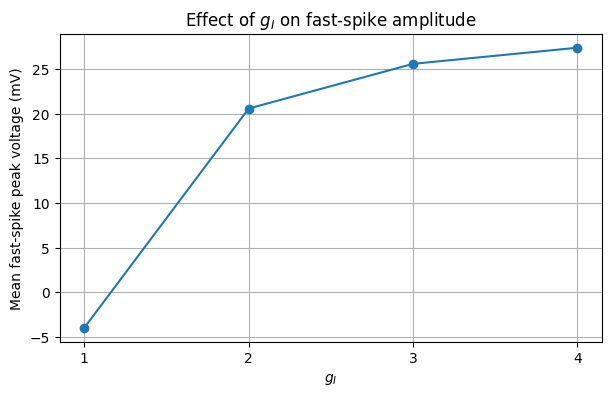

In [59]:
gI_values = [1, 2, 3, 4]
peak_values = [
    mean_peak_voltage[gI]
    for gI in gI_values
]

plt.figure(figsize=(7, 4))

plt.plot(
    gI_values,
    peak_values,
    marker="o"
)

plt.xlabel(r"$g_I$")
plt.ylabel("Mean fast-spike peak voltage (mV)")
plt.title(r"Effect of $g_I$ on fast-spike amplitude")

plt.xticks([1, 2, 3, 4])
plt.grid(True)

plt.show()

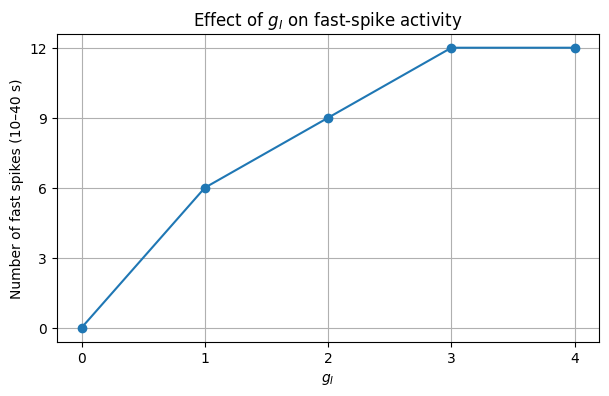

In [60]:
gI_values = [0, 1, 2, 3, 4]

spike_counts = [
    spike_results[gI]["count"]
    for gI in gI_values
]

plt.figure(figsize=(7, 4))

plt.plot(
    gI_values,
    spike_counts,
    marker="o"
)

plt.xlabel(r"$g_I$")
plt.ylabel("Number of fast spikes (10–40 s)")
plt.title(r"Effect of $g_I$ on fast-spike activity")

plt.xticks([0, 1, 2, 3, 4])
plt.yticks([0, 3, 6, 9, 12])
plt.grid(True)

plt.show()

### 6.1 Results

The quantitative analysis confirms that reducing $g_I$ suppresses both the number and amplitude of fast action potentials.

Over the 30 s analysis interval, 12, 12, 9, 6, and 0 fast spikes were detected for $g_I=4,3,2,1,0$, respectively. This corresponds approximately to 4, 4, 3, 2, and 0 fast spikes per burst.

The mean fast-spike peak voltage also decreased as $g_I$ was reduced, from 27.36 mV at $g_I=4$ to 25.56 mV at $g_I=3$, 20.56 mV at $g_I=2$, and -3.96 mV at $g_I=1$. At $g_I=0$, no fast spikes were detected, so a mean fast-spike peak voltage was not defined.

Together, these results show that progressive reduction of the TTX-sensitive inward conductance weakens the fast spiking component of R15 bursting through both a reduction in spike number and a reduction in spike amplitude.

In [62]:
# Locate the continuation point closest to LP1
idx_LP = np.argmin(np.abs(gI_vals - LP1["g_I"]))

# Select one point on each side of LP1
indices = [idx_LP - 2, idx_LP + 2]

for i in indices:
    evals = sol.labels[i]["EP"]["data"]["evals"]

    # Eigenvalue closest to zero
    critical_eigenvalue = min(
        evals,
        key=lambda lam: abs(lam.real)
    )

    print(
        f"g_I = {gI_vals[i]:.6f}, "
        f"V = {V_vals[i]:.6f} mV, "
        f"critical eigenvalue = {critical_eigenvalue.real:.8f}"
    )

g_I = 2.457451, V = -26.334054 mV, critical eigenvalue = -0.00012498
g_I = 2.456886, V = -26.012463 mV, critical eigenvalue = -0.00012501


## 7. Summary

This analysis investigated how reducing the TTX-sensitive inward conductance $g_I$ affects the dynamics of the Plant–Kim R15 neuron model.

Equilibrium continuation was first performed using $g_I$ as the continuation parameter, starting from the untreated value $g_I=4$. A limit point (LP1) was detected at approximately

$$
g_I = 2.457,\qquad V = -26.134\ \text{mV}.
$$

At this point, the equilibrium branch folds and turns back toward increasing $g_I$. Therefore, LP1 represents a change in the equilibrium structure of the model rather than the disappearance of bursting.

Long-term simulations were then performed for $g_I=4,3,2,1,$ and $0$. As $g_I$ was reduced, the fast spiking component of the bursting dynamics was progressively suppressed. The number of detected fast spikes over the 30 s analysis interval decreased from 12 at $g_I=4$ and $g_I=3$, to 9 at $g_I=2$, 6 at $g_I=1$, and 0 at $g_I=0$. The mean fast-spike peak voltage also decreased from 27.36 mV at $g_I=4$ to -3.96 mV at $g_I=1$.

At complete TTX blockade ($g_I=0$), fast action potentials disappeared while the underlying slow membrane-potential oscillation remained. Importantly, bursting was still observed below the equilibrium limit point, showing that LP1 does not directly mark the transition from bursting to slow oscillations.

Overall, reducing $g_I$ progressively suppresses the fast action-potential component of R15 bursting, while the equilibrium fold and the disappearance of fast spiking describe distinct features of the model dynamics.